## Exploratory Data Analysis (EDA) — 100 Interview Questions & Answers

> EDA is where you **understand your data** before building any model.

---

## ============================================================
## **SECTION 1: BASICS (Q1–Q20)—> data loading, shape, info, dtypes, duplicates, wide vs. long format**
## ============================================================

### Q1. What is Exploratory Data Analysis (EDA)?

**Answer:**  
EDA is the process of **analyzing and summarizing datasets** to understand their main characteristics — often using visual methods — before applying formal modeling.

Coined by statistician **John Tukey** in 1977, EDA helps you:
- Discover patterns
- Detect anomalies
- Test hypotheses
- Check assumptions using statistics and graphics

### Q2. Why is EDA important before building ML models?

**Answer:**
- **Understand data structure** — shape, types, ranges
- **Find missing values** before they cause silent errors
- **Detect outliers** that skew models
- **Discover correlations** for feature selection
- **Validate assumptions** required by certain algorithms

> Skipping EDA → wrong conclusions, poor model performance

In [1]:
# Basic EDA Starting Template
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load data
# df = pd.read_csv('data.csv')

# Using a sample dataset for demonstration
from sklearn.datasets import load_iris
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
print('Dataset loaded:', df.shape)

Dataset loaded: (150, 5)


### Q3. What are the main types of EDA?

**Answer:**
- **Univariate** — analyzing one variable at a time (histograms, box plots)
- **Bivariate** — relationship between two variables (scatter plots, correlation)
- **Multivariate** — relationships among 3+ variables (heatmaps, pair plots)

### Q4. What does df.info() tell you?

**Answer:** Returns: **column names**, **non-null counts**, **data types** (int64, object, float64), and **memory usage**. Key for spotting wrong dtypes and missing values at a glance.

In [2]:
# Q4 Demo
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


### Q5. What does df.describe() return?

**Answer:** Returns statistical summary for **numeric columns**: count, mean, std, min, 25th percentile (Q1), median (50%), 75th (Q3), max.

In [3]:
# Q5 Demo
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [4]:
# For categorical too:
df.describe(include='all')

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


### Q6. How do you check the shape and size of a dataset?

In [5]:
print('Shape:', df.shape)        # (rows, columns)
print('Size:', df.size)          # total elements
print('Rows:', len(df))          # row count
print('Columns:', df.columns.tolist())

Shape: (150, 5)
Size: 750
Rows: 150
Columns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']


### Q7. What is the difference between df.head() and df.tail()?

**Answer:** `df.head(n)` returns the **first n rows** (default 5). `df.tail(n)` returns the **last n rows**. Use both — head shows column structure, tail can reveal trailing blank rows or data entry issues.

In [6]:
display(df.head())
display(df.tail())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2
149,5.9,3.0,5.1,1.8,2


### Q8. How do you check data types of all columns?

In [7]:
print(df.dtypes)

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object


In [9]:
# Select only numeric
df_numeric = df.select_dtypes(include='number')
df_numeric

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [10]:
# Select only categorical
df_cat = df.select_dtypes(include='object')
df_cat

""
0
1
2
3
4
...
145
146
147
148


### Q9. What is the difference between structured and unstructured data in EDA?

**Answer:**
- **Structured**: tabular, rows/columns, easily loaded into DataFrames (CSV, SQL). Standard EDA applies directly.
- **Unstructured**: text, images, audio, video. Requires domain-specific EDA — word frequencies, pixel distributions, spectrograms — before feature extraction.

### Q10. How do you find the number of unique values in each column?

In [11]:
print(df.nunique())

sepal length (cm)    35
sepal width (cm)     23
petal length (cm)    43
petal width (cm)     22
target                3
dtype: int64


In [13]:
print(df['target'].value_counts())

target
0    50
1    50
2    50
Name: count, dtype: int64


In [14]:
print(df['target'].value_counts(normalize=True))  # proportions

target
0    0.333333
1    0.333333
2    0.333333
Name: proportion, dtype: float64


### Q11. What is data profiling in EDA?

**Answer:** Data profiling automatically generates a **comprehensive report** of a dataset: column types, missing rates, distributions, correlations, and sample values.

```python
# pip install ydata-profiling
from ydata_profiling import ProfileReport
profile = ProfileReport(df, title='EDA Report')
profile.to_file('report.html')
```

### Q12. What questions do you ask when you first see a new dataset?

**Answer:**
- What does each row represent?
- What is the target variable?
- How many rows/columns? Any obvious duplicates?
- Are there missing values? How many and where?
- What are the data types — are they correct?
- What is the range and distribution of key columns?
- Are there any obvious outliers or errors?

### Q13. How do you detect duplicate rows?

In [15]:
print('Duplicate rows:', df.duplicated().sum())
# View duplicates
# df[df.duplicated()]
# Remove duplicates
df_clean = df.drop_duplicates()
print('After removing:', df_clean.shape)

Duplicate rows: 1
After removing: (149, 5)


### Q14. What is the difference between .loc and .iloc in pandas?

**Answer:**
- `.loc` → label-based indexing (row/column names)
- `.iloc` → integer position-based indexing (0-based)

In [16]:
print(df.loc[0, 'target'])       # label-based
print(df.iloc[0, -1])            # position-based

0
0


### Q15. What is value_counts() and when is it useful?

Returns a **frequency distribution** of a column's values. Most useful for **categorical columns** — reveals class imbalance, rare categories, and typos.

### Q16. How do you detect constant or near-constant columns?

```python
low_var = [c for c in df.columns if df[c].nunique() <= 1]
from sklearn.feature_selection import VarianceThreshold
sel = VarianceThreshold(threshold=0.01)
```

### Q17. What is the role of pandas in EDA?

Pandas is the **primary tool** for tabular EDA in Python. Core capabilities: loading data, reshaping, filtering, grouping, aggregating, merging, and basic plotting.

### Q18. How do you sample a large dataset for EDA?

```python
df.sample(n=1000, random_state=42)     # n rows
df.sample(frac=0.1, random_state=42)   # 10%
```

### Q19. What is the difference between wide and long format data?

- **Wide**: each variable in its own column (one row per subject)
- **Long/tidy**: each observation in its own row

```python
pd.melt(df, id_vars=['id'])   # wide → long
df.pivot(...)                 # long → wide
```

### Q20. When should you reset the index of a DataFrame?

After filtering, dropping rows, or concatenating DataFrames the index may have gaps.

```python
df.reset_index(drop=True, inplace=True)
```

## ============================================================
## **SECTION 2: STATISTICS (Q21–Q40)—> Central tendency, spread, skewness, kurtosis, correlation**
## ============================================================

### Q21. What are measures of central tendency?

- **Mean** — arithmetic average, sensitive to outliers
- **Median** — middle value, robust to outliers
- **Mode** — most frequent value, useful for categorical data

In [17]:
col = 'sepal length (cm)'
print(f'Mean:   {df[col].mean():.3f}')
print(f'Median: {df[col].median():.3f}')
print(f'Mode:   {df[col].mode()[0]:.3f}')

Mean:   5.843
Median: 5.800
Mode:   5.000


### Q22. What are measures of spread / dispersion?

- **Range**: max − min
- **Variance**: average squared deviation from mean
- **Standard deviation**: √variance — same unit as data
- **IQR**: Q3 − Q1, robust measure
- **CV** (Coefficient of Variation): std/mean × 100%

In [18]:
col = 'sepal length (cm)'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
print(f'Range: {df[col].max() - df[col].min():.3f}')
print(f'Variance: {df[col].var():.3f}')
print(f'Std Dev: {df[col].std():.3f}')
print(f'IQR: {IQR:.3f}')
print(f'CV: {df[col].std()/df[col].mean()*100:.2f}%')

Range: 3.600
Variance: 0.686
Std Dev: 0.828
IQR: 1.300
CV: 14.17%


### Q23. What is skewness and how does it affect EDA?

Skewness measures **asymmetry** of a distribution.
- **Positive (right) skew**: long tail to the right, mean > median (e.g., income, house prices)
- **Negative (left) skew**: long tail to the left, mean < median
- **Zero**: symmetric (normal distribution)
- |skew| > 1 = highly skewed

In [19]:
print('Skewness per column:')
print(df.skew(numeric_only=True))

Skewness per column:
sepal length (cm)    0.314911
sepal width (cm)     0.318966
petal length (cm)   -0.274884
petal width (cm)    -0.102967
target               0.000000
dtype: float64


### Q24. What is kurtosis?

Kurtosis measures the **heaviness of tails** compared to a normal distribution.
- **Leptokurtic** (kurtosis > 3): heavy tails, more outliers
- **Platykurtic** (kurtosis < 3): light tails, fewer outliers
- **Mesokurtic**: normal distribution (kurtosis = 3)

In [20]:
print('Kurtosis per column:')
print(df.kurtosis(numeric_only=True))

Kurtosis per column:
sepal length (cm)   -0.552064
sepal width (cm)     0.228249
petal length (cm)   -1.402103
petal width (cm)    -1.340604
target              -1.510135
dtype: float64


### Q25. What is correlation and how is it calculated?

Correlation measures **linear relationship strength** between two variables, ranging from −1 to +1.
- |r| > 0.7 = strong
- 0.3–0.7 = moderate
- < 0.3 = weak

In [21]:
print('Pearson Correlation:')
display(df.corr(numeric_only=True))

# Spearman (rank-based, robust to outliers)
# df.corr(method='spearman')

Pearson Correlation:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
sepal length (cm),1.000000,-0.117570,0.871754,0.817941,0.782561
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126,-0.426658
petal length (cm),0.871754,-0.428440,1.000000,0.962865,0.949035
petal width (cm),0.817941,-0.366126,0.962865,1.000000,0.956547
target,0.782561,-0.426658,0.949035,0.956547,1.000000


### Q26. What is the difference between Pearson and Spearman correlation?

- **Pearson**: measures linear relationship. Assumes normality. Sensitive to outliers.
- **Spearman**: rank-based, measures monotonic relationship. Robust to outliers. Works on non-normal and ordinal data.

➡️ Use Spearman when data is skewed or has outliers.

### Q27. What does a correlation of 0 mean?

It means **no linear relationship** — but does **NOT** mean no relationship at all. Two variables can have zero Pearson correlation but a strong non-linear (e.g., quadratic) relationship. Always plot data alongside computing correlations.

### Q28. What is the difference between covariance and correlation?

- **Covariance**: measures direction of relationship, in original units — hard to interpret magnitude
- **Correlation**: normalized covariance, always between −1 and +1, unitless and interpretable

### Q29. What are quartiles and how are they used in EDA?

- **Q1 (25th percentile)**: 25% of data falls below
- **Q2 (50th / Median)**: 50% below
- **Q3 (75th percentile)**: 75% below
- **IQR = Q3 − Q1**: the middle 50% spread — used for outlier detection and box plots

### Q30. What is a normal distribution and why does it matter in EDA?

A bell-shaped, symmetric distribution with mean = median = mode. Many statistical tests assume normality. Check with: histograms, Q-Q plots, Shapiro-Wilk test, or KS test.

In [22]:
# Normality test
col = 'sepal length (cm)'
stat, p = stats.shapiro(df[col])
print(f'Shapiro-Wilk: stat={stat:.4f}, p={p:.4f}')
print('Normal' if p > 0.05 else 'NOT normal (p < 0.05)')

Shapiro-Wilk: stat=0.9761, p=0.0102
NOT normal (p < 0.05)


### Q31. What is the Central Limit Theorem (CLT)?

CLT states that the **distribution of sample means** approaches a normal distribution as sample size grows (n ≥ 30), regardless of the population's distribution. This is why many statistical methods work even with non-normal data when sample size is large enough.

### Q32. What is a p-value in the context of EDA statistical tests?

A p-value is the probability of observing results as extreme as the data, assuming the null hypothesis is true.
- **p < 0.05**: reject null hypothesis (statistically significant)
- **p ≥ 0.05**: fail to reject null hypothesis

### Q33. How do you check if a variable is normally distributed?

```python
# Q-Q Plot (visual)
stats.probplot(df['col'], dist='norm', plot=plt)

# Shapiro-Wilk test (n < 5000)
stats.shapiro(df['col'])

# Kolmogorov-Smirnov test
stats.kstest(df['col'], 'norm')
```

### Q34. What is a chi-squared test and when is it used?

Tests **independence between two categorical variables**.

```python
from scipy.stats import chi2_contingency
ct = pd.crosstab(df['Gender'], df['Purchase'])
chi2, p, dof, expected = chi2_contingency(ct)
# p < 0.05 → variables are NOT independent
```

### Q35. What is a confidence interval?

A range of values that, with a specified probability (e.g., 95%), contains the true population parameter.

```python
ci = stats.t.interval(0.95, df=len(df)-1,
       loc=df['col'].mean(), scale=stats.sem(df['col']))
```

### Q36. What is multicollinearity and how do you detect it?

Occurs when two or more predictor variables are highly correlated. Detected using VIF (Variance Inflation Factor). VIF > 10 = high multicollinearity.

```python
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
```

### Q37. What is the difference between population and sample statistics?

- **Population**: the entire group (parameter, e.g., μ, σ)
- **Sample**: a subset (statistic, e.g., x̄, s)

Pandas calculates **sample statistics** by default (ddof=1 for std).

### Q38. What is ANOVA and when would you use it?

Analysis of Variance tests whether **means of 3+ groups are significantly different**.

```python
from scipy.stats import f_oneway
f_oneway(group1, group2, group3)  # p < 0.05: at least one group mean differs
```

### Q39. What is entropy in the context of EDA?

Entropy measures **randomness or disorder** in a variable. High entropy = high diversity.

```python
from scipy.stats import entropy
probs = df['col'].value_counts(normalize=True)
entropy(probs, base=2)  # bits
```

### Q40. What is a cross-tabulation and when is it used?

A frequency table of two categorical variables showing how they co-occur.

```python
pd.crosstab(df['Gender'], df['Purchased'], normalize='index')
```

## ============================================================
## **SECTION 3: MISSING DATA (Q41–Q55)—> Imputation strategies, KNN imputation, missing no visualization**
## ============================================================

### Q41. How do you find missing values in a DataFrame?

In [23]:
# Inject some missing values for demo
import numpy as np
df_missing = df.copy()
df_missing.iloc[5:15, 0] = np.nan
df_missing.iloc[20:25, 2] = np.nan

print('Missing count per column:')
print(df_missing.isnull().sum())
print('\nMissing % per column:')
print(df_missing.isnull().mean() * 100)
print(f'\nTotal missing cells: {df_missing.isnull().sum().sum()}')

Missing count per column:
sepal length (cm)    10
sepal width (cm)      0
petal length (cm)     5
petal width (cm)      0
target                0
dtype: int64

Missing % per column:
sepal length (cm)    6.666667
sepal width (cm)     0.000000
petal length (cm)    3.333333
petal width (cm)     0.000000
target               0.000000
dtype: float64

Total missing cells: 15


### Q42. What are the three types of missing data mechanisms?

- **MCAR** (Missing Completely At Random): missingness has no pattern — safe to drop rows
- **MAR** (Missing At Random): missingness depends on other observed variables — imputation possible
- **MNAR** (Missing Not At Random): missingness depends on the missing value itself — hardest to handle

### Q43. When is it appropriate to drop rows with missing values?

- The proportion of missing data is **small** (< 5%)
- The missing mechanism is **MCAR**
- The dataset is **large enough** to lose rows
- The column is not crucial to the analysis

```python
df.dropna(subset=['critical_col'], inplace=True)
```

### Q44. What is mean/median/mode imputation and when should each be used?

- **Mean imputation**: for normally distributed numeric columns
- **Median imputation**: for skewed numeric columns or those with outliers (more robust)
- **Mode imputation**: for categorical columns

```python
df['Age'].fillna(df['Age'].median(), inplace=True)
df['City'].fillna(df['City'].mode()[0], inplace=True)
```

### Q45. What is forward fill and backward fill?

Used primarily for **time-series data** where the previous or next known value is the best estimate.

```python
df.ffill()   # forward fill
df.bfill()   # backward fill
```

### Q46. What is KNN imputation?

Imputes missing values using the **mean/mode of k nearest neighbors** based on other features.

```python
from sklearn.impute import KNNImputer
imputer = KNNImputer(n_neighbors=5)
df_imputed = imputer.fit_transform(df)
```

### Q47. What is multiple imputation?

Creates **multiple complete datasets** by imputing missing values multiple times with random variation, then combines results. Library: `sklearn.impute.IterativeImputer` (MICE algorithm).

### Q48. How do you visualize missing data patterns?

```python
import missingno as msno
msno.matrix(df)      # matrix of presence/absence
msno.heatmap(df)     # correlation of missingness
msno.bar(df)         # bar chart of completeness
```

### Q49. Should you drop or impute a column with 60% missing values?

Generally **drop it** — more than 50% missing makes imputation unreliable because you are inventing data, not filling gaps. The imputed values will dominate the column's distribution and introduce heavy bias.

### Q50. What is a missing indicator variable?

A binary column added to flag that a value was missing — allows the model to learn that missingness itself is informative.

```python
df['Age_missing'] = df['Age'].isnull().astype(int)
df['Age'].fillna(df['Age'].median(), inplace=True)
```

### Q51. How does missing data affect ML models differently?

- **Tree-based models** (XGBoost, LightGBM): can handle NaN natively
- **Linear models, SVMs, KNN**: crash or give wrong results — must impute first
- **Neural networks**: typically need imputation

### Q52. What is the difference between None and NaN in pandas?

`None` is Python's null object; `NaN` is a float ("Not a Number"). Pandas converts `None` to `NaN` in numeric columns. Both are detected by `isnull()`.

### Q53. How do you impute missing values differently for train and test sets?

Fit the imputer **only on training data**, then transform both. Never fit on test data — it leaks information.

```python
imputer.fit(X_train)
X_train = imputer.transform(X_train)
X_test  = imputer.transform(X_test)   # NOT fit again
```

### Q54. What is listwise deletion vs pairwise deletion?

- **Listwise**: removes entire row if any value is missing (default `df.dropna()`)
- **Pairwise**: uses all available data for each calculation, per-pair

### Q55. How do you handle missing values in time-series data?

```python
df['val'].interpolate(method='linear')    # linear interpolation
df['val'].interpolate(method='time')      # time-aware
df.ffill()  # or bfill()
```

## ============================================================
## **SECTION 4: OUTLIERS (Q56–Q67)—> IQR method, Z-score**
## ============================================================

### Q56. What is an outlier?

A data point that **differs significantly from other observations**. Can be a genuine extreme value, a data entry error, or a measurement mistake. Always investigate before removing.

### Q57. How do you detect outliers using IQR?

In [24]:
col = 'sepal length (cm)'
Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df[col] < lower) | (df[col] > upper)]
print(f'IQR bounds: [{lower:.2f}, {upper:.2f}]')
print(f'Outliers found: {len(outliers)}')

IQR bounds: [3.15, 8.35]
Outliers found: 0


### Q58. How do you detect outliers using the Z-score method?

In [25]:
col = 'sepal length (cm)'
z_scores = np.abs(stats.zscore(df[col]))
outliers_z = df[z_scores > 3]
print(f'Z-score outliers (|z| > 3): {len(outliers_z)}')

Z-score outliers (|z| > 3): 0


### Q59. What is a box plot and how does it show outliers?

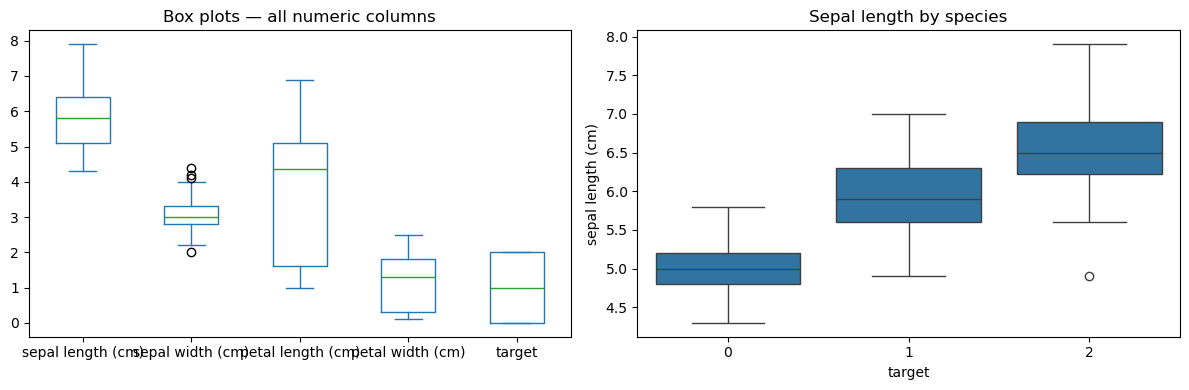

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.plot.box(ax=axes[0])
axes[0].set_title('Box plots — all numeric columns')

sns.boxplot(x='target', y='sepal length (cm)', data=df, ax=axes[1])
axes[1].set_title('Sepal length by species')
plt.tight_layout()
plt.show()

### Q60. What are different strategies to handle outliers?

- **Remove**: if clearly data entry errors
- **Cap/Winsorize**: clip to a percentile boundary
- **Transform**: log, sqrt to compress the range
- **Separate model**: model outliers separately
- **Keep**: if outliers are genuine and informative

### Q61. What is Winsorization?

Capping extreme values to a specified percentile — e.g., set all values above 99th percentile to the 99th percentile value.

```python
from scipy.stats.mstats import winsorize
df['col'] = winsorize(df['col'], limits=[0.01, 0.01])
```

### Q62. What is the difference between univariate and multivariate outliers?

- **Univariate**: extreme in a single variable (caught by IQR, Z-score, box plot)
- **Multivariate**: not extreme in any single dimension but unusual in combination — detected with Mahalanobis distance or Isolation Forest

### Q63. What is the Isolation Forest algorithm for outlier detection?

Isolation Forest isolates anomalies by **randomly partitioning** data — outliers are easier to isolate and require fewer splits.

```python
from sklearn.ensemble import IsolationForest
iso = IsolationForest(contamination=0.05, random_state=42)
df['outlier'] = iso.fit_predict(df[['col1','col2']])
# -1 = outlier, 1 = inlier
```

### Q64. How does Local Outlier Factor (LOF) work?

LOF compares the **local density** of a point to its neighbors. Points with much lower density than neighbors are outliers.

```python
from sklearn.neighbors import LocalOutlierFactor
lof = LocalOutlierFactor(n_neighbors=20)
labels = lof.fit_predict(df_numeric)
```

### Q65. Should you always remove outliers?

**No.** Outliers can be genuine and informative — in fraud detection, the outliers ARE what you want to find. Always ask: is this a data error or a real extreme value? For tree-based models, outliers have minimal effect. For linear regression, they distort results significantly.

### Q66. How does a log transformation help with outliers?

Log transformation **compresses the range** of right-skewed data, reducing the influence of extreme high values.

```python
df['log_income'] = np.log1p(df['income'])  # log(1+x) handles zeros safely
```

### Q67. What is Cook's Distance?

Measures the **influence of each data point** on a regression model's coefficients. High Cook's D (> 4/n) indicates a potentially influential outlier.

```python
import statsmodels.api as sm
influence = sm.OLS(y, X).fit().get_influence()
cooks = influence.cooks_distance[0]
```

## ============================================================
## **SECTION 5: VISUALIZATION (Q68–Q80)—> histogram, heatmap, pair plot**
## ============================================================

### Q68. What are the main Python libraries for EDA visualization?

- **Matplotlib**: base plotting library, highly customizable
- **Seaborn**: statistical plots, works on DataFrames, cleaner defaults
- **Plotly**: interactive charts
- **Bokeh**: web-based interactive visualizations
- **Altair**: declarative grammar of graphics

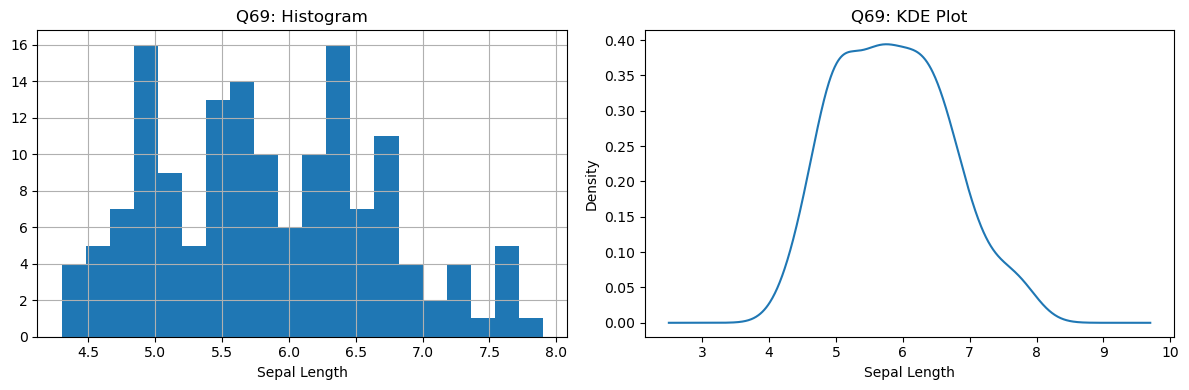

In [27]:
# Q69 — Histogram vs KDE
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['sepal length (cm)'].hist(bins=20, ax=axes[0])
axes[0].set_title('Q69: Histogram')
axes[0].set_xlabel('Sepal Length')

df['sepal length (cm)'].plot.kde(ax=axes[1])
axes[1].set_title('Q69: KDE Plot')
axes[1].set_xlabel('Sepal Length')

plt.tight_layout()
plt.show()

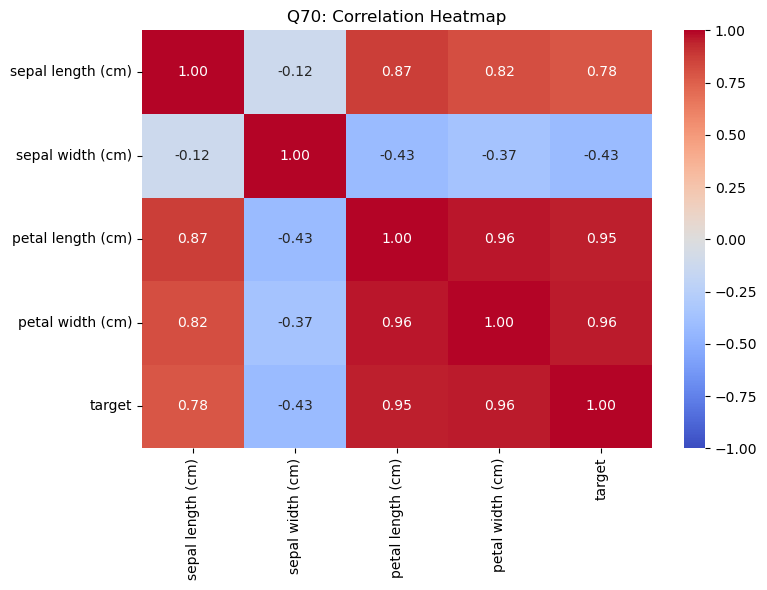

In [28]:
# Q70 — Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm',
            vmin=-1, vmax=1, fmt='.2f')
plt.title('Q70: Correlation Heatmap')
plt.tight_layout()
plt.show()

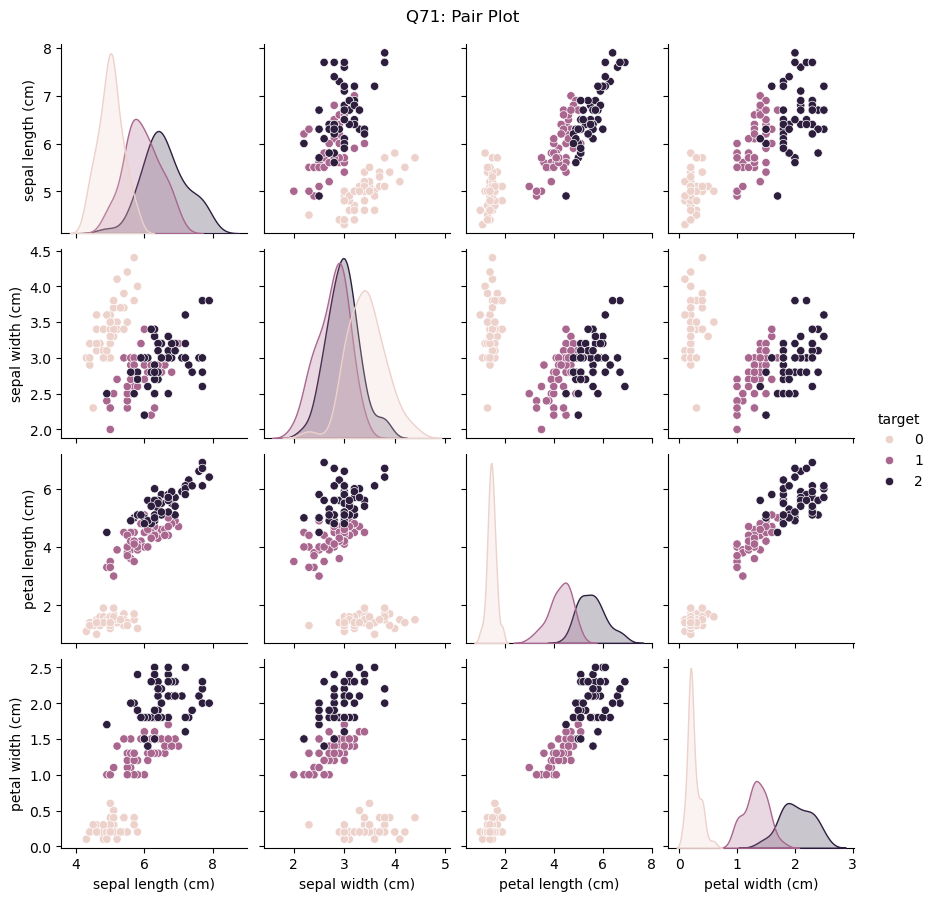

In [29]:
# Q71 — Pair Plot
sns.pairplot(df, hue='target', diag_kind='kde', height=2.2)
plt.suptitle('Q71: Pair Plot', y=1.02)
plt.show()

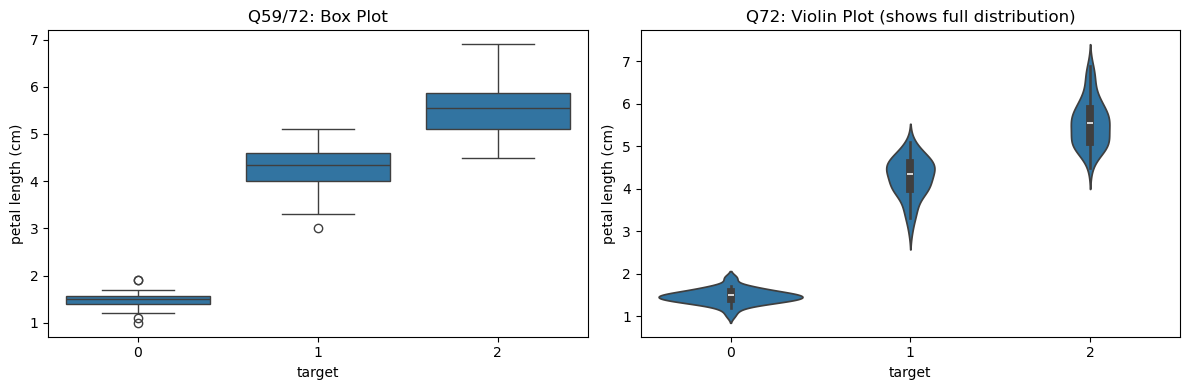

In [30]:
# Q72 — Violin Plot vs Box Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x='target', y='petal length (cm)', data=df, ax=axes[0])
axes[0].set_title('Q59/72: Box Plot')

sns.violinplot(x='target', y='petal length (cm)', data=df, ax=axes[1])
axes[1].set_title('Q72: Violin Plot (shows full distribution)')

plt.tight_layout()
plt.show()

In [ ]:
# Q74 — Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

stats.probplot(df['sepal length (cm)'], dist='norm', plot=axes[0])
axes[0].set_title('Q74: Q-Q Plot — Sepal Length')

stats.probplot(df['petal length (cm)'], dist='norm', plot=axes[1])
axes[1].set_title('Q74: Q-Q Plot — Petal Length')

plt.tight_layout()
plt.show()

### Q73. When would you use a bar chart vs a histogram?

- **Bar chart**: for **categorical variables** — frequency or aggregate of categories
- **Histogram**: for **continuous/numeric variables** — frequency distribution across bins

### Q75. What is a scatter plot used for in EDA?

Scatter plots show the **relationship between two continuous variables** — reveals direction, strength, and shape of relationship, and highlights outliers.

### Q76. What is a count plot and when is it useful?

A count plot shows the count of each category. Adding `hue` allows comparison across a second category.

```python
sns.countplot(x='Gender', hue='Purchased', data=df)
```

### Q77. How do you visualize class imbalance?

```python
sns.countplot(x='target', data=df)
df['target'].value_counts().plot.pie(autopct='%1.1f%%')
```

### Q78. What is a swarm plot?

Shows **all individual data points** distributed without overlap. Great for small-to-medium datasets.

```python
sns.swarmplot(x='Category', y='Score', data=df)
```

### Q79. When would you use a line plot in EDA?

Line plots are best for **time-series or sequential data** where order matters.

### Q80. What is a facet grid and when is it useful?

Creates a **grid of plots**, one per category, allowing comparison of distributions across groups simultaneously.

```python
g = sns.FacetGrid(df, col='Region', row='Year')
g.map(sns.histplot, 'Revenue')
```

## ============================================================
## **SECTION 6: FEATURE ENGINEERING (Q81–Q93)—> encoding, scaling, binning, PCA, target encoding, datetime expansion**
## ============================================================

### Q81. What is feature engineering and why does it happen after EDA?

Feature engineering creates new variables or transforms existing ones to **improve model performance**. EDA must come first — you need to understand the data's structure, distributions, relationships, and issues before you can engineer features meaningfully.

### Q82. What is one-hot encoding and when is it used?

Converts **categorical variables into binary columns** — one column per category. Used for nominal (no order) categorical variables.

```python
pd.get_dummies(df, columns=['Color'], drop_first=True)
```

### Q83. What is label encoding vs ordinal encoding?

- **Label encoding**: assigns an integer to each category (0, 1, 2...). Implies an order — use only for ordinal variables or tree-based models.
- **Ordinal encoding**: explicitly assigns integers based on known order (Low=0, Medium=1, High=2)

### Q84. What is feature scaling and why is it needed?

Scaling brings all features to a **comparable range**. Needed for KNN, SVM, K-means, linear regression, and neural networks. Not needed for tree-based models.

### Q85. What is the difference between StandardScaler and MinMaxScaler?

- **StandardScaler**: mean=0, std=1. Best when data is approximately normal.
- **MinMaxScaler**: scales to [0, 1]. Sensitive to outliers.

### Q86. What is binning (discretization) and when is it useful?

Converts a continuous variable into **discrete intervals**.

```python
df['age_group'] = pd.cut(df['age'], bins=[0,18,35,60,100],
                          labels=['child','young','adult','senior'])
```

### Q87. How do you create interaction features?

```python
df['BMI'] = df['weight'] / (df['height'] ** 2)
df['age_income'] = df['age'] * df['income']
```

### Q88. What is target encoding?

Replaces a category with the **mean of the target variable** for that category. Powerful for high-cardinality categoricals but risks data leakage — must be done with cross-validation.

```python
mean_enc = df.groupby('City')['price'].mean()
df['City_encoded'] = df['City'].map(mean_enc)
```

### Q89. What is feature selection and how does EDA guide it?

Feature selection chooses the **most relevant features**. EDA guides it via: correlation analysis, variance analysis, and domain knowledge.

```python
# Drop highly correlated features
corr = df.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if any(upper[c] > 0.9)]
```

### Q90. What is a datetime feature expansion?

```python
df['year']       = df['date'].dt.year
df['month']      = df['date'].dt.month
df['day']        = df['date'].dt.day
df['weekday']    = df['date'].dt.weekday
df['quarter']    = df['date'].dt.quarter
df['is_weekend'] = df['weekday'].isin([5,6]).astype(int)
```

### Q91. What is RobustScaler and when should you use it?

Uses **median and IQR** instead of mean and std — robust to outliers.

```python
from sklearn.preprocessing import RobustScaler
X_scaled = RobustScaler().fit_transform(X)
```

### Q92. What is the curse of dimensionality?

As the number of features increases, the volume of the feature space grows exponentially — data becomes **sparse**, distances become meaningless, and models overfit. EDA helps identify and remove redundant features early.

### Q93. What is PCA and how does it relate to EDA?

Principal Component Analysis reduces dimensionality by finding **principal components** (directions of maximum variance). In EDA, it visualizes high-dimensional data in 2D/3D.

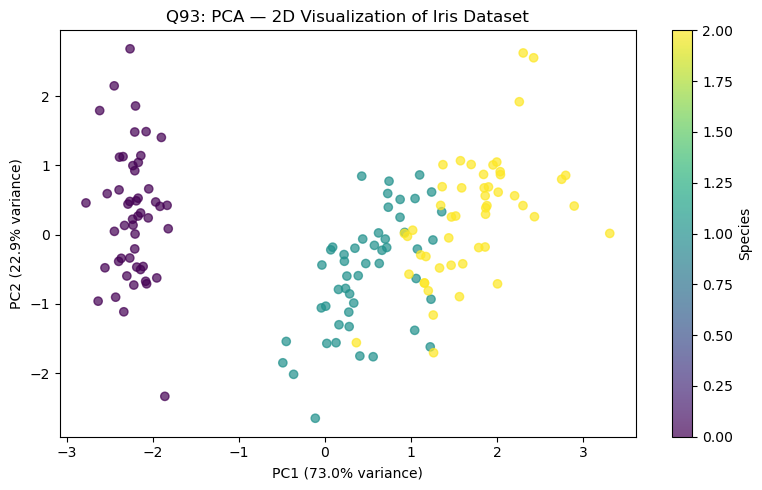

Total variance explained: 95.8%


In [31]:
# Q93 — PCA Visualization
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X = df.drop('target', axis=1)
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['target'], cmap='viridis', alpha=0.7)
plt.colorbar(scatter, label='Species')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.title('Q93: PCA — 2D Visualization of Iris Dataset')
plt.tight_layout()
plt.show()
print(f'Total variance explained: {sum(pca.explained_variance_ratio_)*100:.1f}%')

## ============================================================
## **SECTION 7: ADVANCED (Q94–Q100)—> EDA vs. CDA, time-series EDA, data drift, text EDA, Kaggle workflow**
## ============================================================

### Q94. What is the difference between EDA and CDA (Confirmatory Data Analysis)?

- **EDA**: open-ended exploration to discover patterns, generate hypotheses. No predefined questions.
- **CDA**: starts with a specific hypothesis and uses statistical tests to confirm or reject it.

➡️ EDA comes first to inform CDA hypotheses.

### Q95. How does EDA differ for imbalanced datasets?

- Report **class distribution** early — identify imbalance ratio
- Analyze feature distributions **per class** to find discriminating features
- Use **stratified sampling** when splitting
- Focus on recall, F1, AUC-ROC — not just accuracy
- Consider SMOTE or class weighting after EDA reveals imbalance

### Q96. What is EDA for time-series data?

- **Trend**: long-term increase/decrease
- **Seasonality**: repeating patterns
- **Stationarity**: is mean/variance constant over time? (ADF test)
- **Autocorrelation**: ACF/PACF plots to see lag relationships
- **Missing timestamps**: check for gaps

```python
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['value'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])  # p < 0.05 = stationary
```

### Q97. What is data drift and how does EDA help detect it?

Data drift occurs when the **statistical properties of input data change over time**, degrading model performance in production.

EDA detects it by comparing distributions: train vs. new data histograms, KS tests, PSI (Population Stability Index) scores.

```python
# Kolmogorov-Smirnov test for drift
from scipy.stats import ks_2samp
stat, p = ks_2samp(train_data['col'], new_data['col'])
print('Drift detected!' if p < 0.05 else 'No drift')
```

### Q98. How do you approach EDA for a text dataset?

- **Text length** distribution (words, characters)
- **Word frequency**: top-n words, word clouds
- **Vocabulary size**, unique tokens
- **Language detection** if multilingual
- **Sentiment distribution** (if labeled)
- **N-gram analysis** for common phrases

### Q99. What is the difference between a feature importance plot and a correlation heatmap?

- **Correlation heatmap**: shows pairwise linear relationships between all features. EDA phase, model-agnostic. Good for multicollinearity detection.
- **Feature importance**: model-specific measure (e.g., Gini impurity for trees) showing how much each feature contributes to predictions. Post-modeling phase.

### Q100. What is the EDA workflow for a Kaggle competition?

| Step | Action |
|---|---|
| 1 | Load & shape: rows, columns, dtypes |
| 2 | Missing values: map and plan imputation |
| 3 | Target analysis: distribution, imbalance, leakage check |
| 4 | Univariate: distributions of all features |
| 5 | Bivariate: each feature vs. target |
| 6 | Correlation: heatmap, multicollinearity |
| 7 | Outliers: detect and decide |
| 8 | Feature ideas: hypothesize new features from EDA insights |

---
## BONUS: Complete EDA Template (Copy & Use)

A ready-to-use EDA function you can apply to any dataset.

EXPLORATORY DATA ANALYSIS REPORT

 Shape: 150 rows × 5 columns

 Data Types:
float64    4
int64      1
Name: count, dtype: int64

 Missing Values (0 columns affected):
 No missing values!

 Duplicate Rows: 1 (0.67%)

 Statistical Summary (Numeric):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



 Skewness (|skew| > 1 = highly skewed):
sepal width (cm)     0.318966
sepal length (cm)    0.314911
target               0.000000
petal width (cm)    -0.102967
petal length (cm)   -0.274884
dtype: float64

 Outlier Count (IQR method):
  sepal width (cm): 4 outliers

 Target Variable: target
target
0    50
1    50
2    50
Name: count, dtype: int64


IndexError: index 0 is out of bounds for axis 0 with size 0

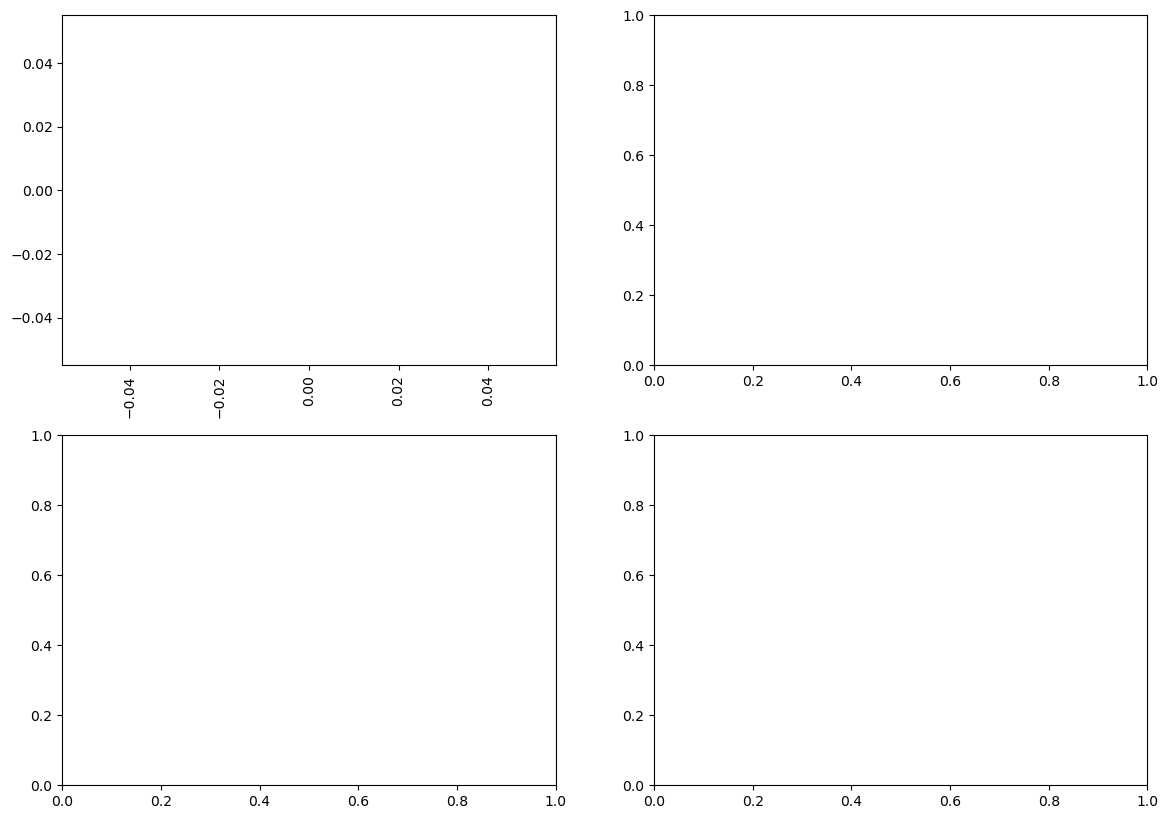

In [32]:
def full_eda(df, target=None):
    """Complete EDA template for any DataFrame."""
    print('=' * 60)
    print('EXPLORATORY DATA ANALYSIS REPORT')
    print('=' * 60)

    # 1. Shape
    print(f'\n Shape: {df.shape[0]} rows × {df.shape[1]} columns')

    # 2. Data types
    print('\n Data Types:')
    print(df.dtypes.value_counts())

    # 3. Missing values
    missing = df.isnull().sum()
    missing_pct = (df.isnull().mean() * 100).round(2)
    missing_df = pd.DataFrame({'Missing': missing, 'Missing %': missing_pct})
    missing_df = missing_df[missing_df['Missing'] > 0].sort_values('Missing %', ascending=False)
    print(f'\n Missing Values ({len(missing_df)} columns affected):')
    if len(missing_df) > 0:
        print(missing_df)
    else:
        print(' No missing values!')

    # 4. Duplicates
    n_dup = df.duplicated().sum()
    print(f'\n Duplicate Rows: {n_dup} ({n_dup/len(df)*100:.2f}%)')

    # 5. Statistical summary
    print('\n Statistical Summary (Numeric):')
    display(df.describe())

    # 6. Skewness
    numeric_cols = df.select_dtypes(include='number').columns
    skew = df[numeric_cols].skew().sort_values(ascending=False)
    print('\n Skewness (|skew| > 1 = highly skewed):')
    print(skew)

    # 7. Outliers (IQR)
    print('\n Outlier Count (IQR method):')
    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        n_out = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
        if n_out > 0:
            print(f'  {col}: {n_out} outliers')

    # 8. Target analysis
    if target and target in df.columns:
        print(f'\n Target Variable: {target}')
        print(df[target].value_counts())

    # 9. Plots
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Missing values bar
    miss_pct = df.isnull().mean() * 100
    miss_pct[miss_pct > 0].plot.bar(ax=axes[0,0], color='salmon')
    axes[0,0].set_title('Missing Value % per Column')
    axes[0,0].set_ylabel('Missing %')

    # Correlation heatmap
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm',
                vmin=-1, vmax=1, fmt='.2f', ax=axes[0,1])
    axes[0,1].set_title('Correlation Heatmap')

    # Distributions
    df[numeric_cols].hist(ax=axes[1,0], bins=20, edgecolor='white')
    axes[1,0].set_title('Feature Distributions')

    # Box plots
    df[numeric_cols].plot.box(ax=axes[1,1])
    axes[1,1].set_title('Box Plots (Outlier Detection)')

    plt.tight_layout()
    plt.show()
    print('\n EDA Complete!')


# Run on Iris dataset
full_eda(df, target='target')

---
## 📋 Quick Reference Summary

| Task | Command |
|---|---|
| Shape | `df.shape` |
| Data types | `df.dtypes` / `df.info()` |
| Statistics | `df.describe()` |
| Missing values | `df.isnull().sum()` |
| Unique values | `df.nunique()` / `df['col'].value_counts()` |
| Duplicates | `df.duplicated().sum()` |
| Correlation | `df.corr()` |
| Skewness | `df.skew()` |
| IQR Outliers | `Q1 - 1.5*IQR` to `Q3 + 1.5*IQR` |
| Z-score Outliers | `z_scores > 3` |
| Fill missing | `df.fillna(df.median())` |
| Drop missing | `df.dropna()` |
| Histogram | `df['col'].hist()` |
| Box plot | `sns.boxplot(x=df['col'])` |
| Heatmap | `sns.heatmap(df.corr(), annot=True)` |
| Pair plot | `sns.pairplot(df, hue='target')` |
| Normality test | `stats.shapiro(df['col'])` |
| PCA | `PCA(n_components=2).fit_transform(X)` |

---